# Principal Component Analysis (PCA)

**Problem:** Given a matrix $A$ (treat $A$ as a dataset) of size $(m,n)$, find unitary matrix $W$ of size $(p,p)$ (treat $W$ as a transformation - data engineering), such that we can use $W$ to transform $A$ into
$$
T = A * W
$$,
where $T$ captures most of the information from $A$.

**Solution:** Using SVD of the matrix

- Decompose $A$ into
$$
A = U * \Sigma * V^T
$$

- Define $W = V$, then $T = A * W + (A = U * \Sigma * V^T)*V = U*\Sigma$.

**Example:** Generate a random matrix, find the matrix $W$ and compute $T$ as the projection of $A$ on the new space $W$.

In [65]:
import numpy as np

In [66]:
A = np.random.randint(low=-3, high=20, size=(1000, 30))

In [67]:
print(A.shape)

(1000, 30)


In [68]:
U, S, VT = np.linalg.svd(A)

In [69]:
W = VT.T

In [70]:
T = A @ W

- Basic of Machine Learning
- USe PCA to engineer the data before training
- Apply to the classification problem

**Example:** Suppose we have the data from 1000 clients from a bank, each client we collect 25 values. Now we have the matrix $A$ of size $(1000,25)$, then we need determine if we can approve for credit card or not.

- $A$ as input data
- $y$ as the output: Yes or 1, No or 0.

In [71]:
import numpy as np

Use scikit-learn package

In [72]:
%pip install scikit-learn


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [73]:
# generate a data
from sklearn.datasets import make_classification

In [74]:
A, y = make_classification(
    n_samples=1000, # number of rows
    n_features=25, # number of cols
    n_classes=2, # yes or no
    class_sep=2.0
)

In [75]:
print(A.shape)

(1000, 25)


In [76]:
print(y[:10])

[0 1 1 1 1 0 0 0 1 1]


Train a ML model for classification: LogRegression

In [77]:
from sklearn.linear_model import LogisticRegression

In [78]:
# initiate the model
model = LogisticRegression(max_iter=1000)

In [79]:
# train the model to make it learn the data from the past
model.fit(A, y)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [80]:
score = model.score(A, y)

In [81]:
print(score)

0.994


In [82]:
pred = model.predict(A)

In [83]:
print(pred[:10])

[0 1 1 1 0 0 0 0 1 1]


In [84]:
print(y[:10])

[0 1 1 1 1 0 0 0 1 1]


- Pick a dataset (classify the fashion images)
- Use LogRegression to train on the raw data, compute the score
- Apply the PCA to reduce the dimension, then retrain the model.

In [85]:
data = np.load("fashion_small.npz")

In [86]:
print(data)

NpzFile 'fashion_small.npz' with keys: x_train, y_train, x_test, y_test


In [87]:
X_train = data["x_train"]
y_train = data["y_train"]

In [88]:
X_test = data["x_test"]
y_test = data["y_test"]

In [89]:
print(X_train.shape)

(10000, 28, 28)


This dataset contains 10000 images, each of which has the dimension 28x28

In [90]:
# extract the first image
first_img = X_train[0]
print(first_img.shape)

(28, 28)


In [91]:
import matplotlib.pyplot as plt

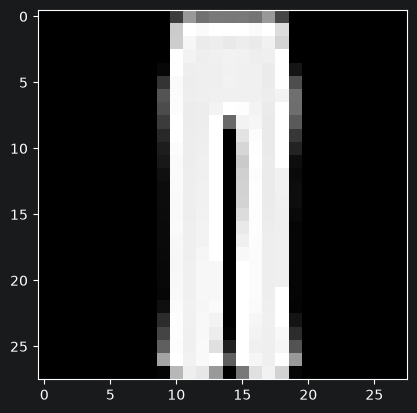

In [92]:
# plot it to see the actual image
fig, ax = plt.subplots()

ax.imshow(first_img, cmap="gray") # use gray scale

plt.show()

In [93]:
# we can get the label
first_label = y_train[0]
print(first_label)

1


In [94]:
# the order of the objects
NAMES = [
    "T-Shirt",
    "Trousers",
    "Pullover",
    "Dress",
    "Coat",
    "Sandals",
    "Shirt",
    "Sneaker",
    "Bags",
    "Ankle boot",
]

Take random 10 images and plot them with all labels

In [95]:
# pick random indices
pick = np.random.choice(10_000, 10, replace=False)
print(pick)

[5611 2630 8696 6106 2482 4357 5196 2052 6048  953]


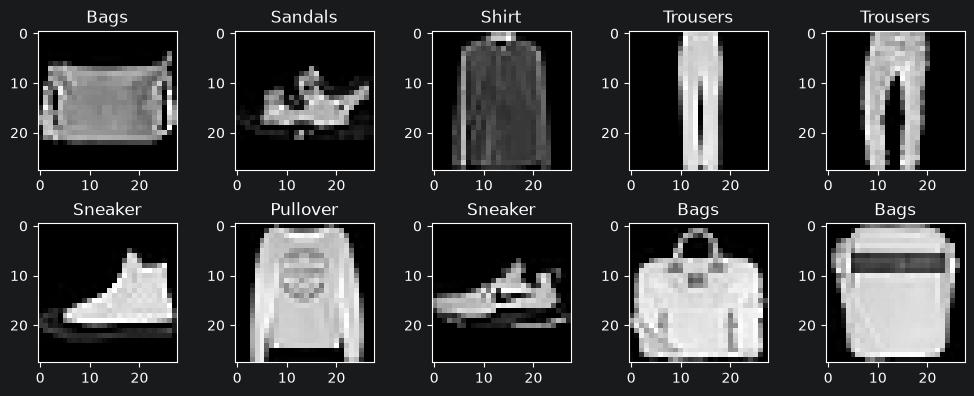

In [96]:
# plot them in 2 rows, 5 cols
fig, axs = plt.subplots(nrows=2, ncols=5, figsize=(10, 4))

for i, idx in enumerate(pick):
    img_i = X_train[idx]
    row_idx = i // 5
    col_idx = i % 5
    label_i = NAMES[y_train[idx]]
    axs[row_idx, col_idx].imshow(img_i, cmap="gray")
    # add the label
    axs[row_idx, col_idx].set_title(label_i)

plt.tight_layout()
plt.show()

How to train this data with LogRegression?

- Flatten each image into a vector
- For a matrix A, use A and y_train to fit into model

In [97]:
# flatten first image
first_vector = first_img.reshape(-1)

In [98]:
print(first_vector.shape)

(784,)


In [99]:
A = X_train.reshape(10_000, 784)

In [100]:
print(A.shape)

(10000, 784)


In [101]:
# init the model
model = LogisticRegression(max_iter=4000)

In [102]:
import time

In [103]:
# train the model (fit)
model.fit(A, y_train)

/Users/maddox/progz/MATH-311/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 4000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=4000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",4000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [104]:
print(X_test.shape)

(2000, 28, 28)


In [105]:
# flatten the X_test first
X_vector = X_test.reshape(2_000, 784)

In [106]:
# check the score
score = model.score(X_vector, y_test)

In [107]:
print(score)

0.764


In previous part, we trained the model with accuracy $score=0.764$, running in $23.5$ seconds.

In training the model, it is better to work with data that is centered at zero!
We can do a simple engineering to improve the score:

- Compute the sample means of all columns
- Compute the sample std of all columns
- Normalize it using standardization.
- Retrain the model

In [108]:
# compute the mean for each column
mean = A.mean(axis=0)

In [109]:
# make sure mean has 784 values
print(mean.shape)

(784,)


In [110]:
# compute the std
std = A.std(axis=0) # compute along the x axis

In [111]:
# normalize the matrix A
A_scaled = (A - mean) / std

In [112]:
# A_scaled and y_train to train the model
model = LogisticRegression(max_iter=1000)

In [113]:
import time

In [114]:
start_time = time.time()
model.fit(A_scaled, y_train)
end_time = time.time()
running_time = end_time - start_time

In [115]:
# apply the normalization to B before testing!
B_scaled = (B - mean) / std

In [117]:
# check the score
score = model.score(B_scaled, y_test)
print(score)

0.804


After normalization, the score goes up to $0.804$

PCA engineering further more on `A_scaled` and retrain the model:

- Decompose $A_{scaled} = U*\Sigma * V^T$
- Set the matrix as first $k$ prinicipal components

$$W = V[:,:k]$$
- Transform the data
$$
T_{train} = A_{scaled}*W
$$


In [118]:
U, S, VT = np.linalg.svd(A_scaled)

In [119]:
k = 10
W = VT.T[:,:k]

In [121]:
# Transform the trained dataset
T_train = A_scaled @ W

In [122]:
# Transform the test dataset
T_test = B_scaled @ W

In [123]:
model = LogisticRegression(max_iter=1000)

In [124]:
start_time = time.time()
model.fit(T_train, y_train)
end_time = time.time()
pca_running_time = end_time - start_time

In [125]:
print(pca_running_time)

1.213426113128662


In [127]:
pca_score = model.score(T_test, y_test)
print(pca_score)

0.7435


Write a function to cut the principal components to $k$ and train the model to return the running time, the score

In [130]:
def pca_train(A, B, y_train, y_test, k, mean, std):
    # A is the training dataset
    # B is the testing dataset
    # return the time, score
    A_scaled = (A - mean) / std
    B_scaled = (B - mean) / std
    model = LogisticRegression(max_iter=1000)
    U, S, VT = np.linalg.svd(A_scaled)
    W = VT.T[:,:k]
    T_train = A_scaled @ W
    T_test = B_scaled @ W
    # fit the model
    start_time = time.time()
    model.fit(T_train, y_train)
    end_time = time.time()
    exec_time = end_time - start_time
    # compute the score
    score = model.score(T_test, y_test)
    return exec_time, score

In [133]:
pca_train(A, B, y_train, y_test, k=25, mean=mean, std=std)

/Users/maddox/progz/MATH-311/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


(1.4408481121063232, 0.802)

For this dataset , we can select 25 key principal component to train with 2.5 time less, and obtain the accuracy of avbout the same, score = 0.802 vs original score = 0.804.

Check what the model can see from the transformed images

In [135]:
first_img = A[200]
print(first_img.shape)

(784,)


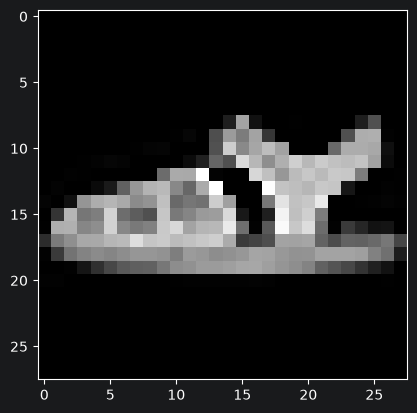

In [139]:
#plot this image
fig, ax = plt.subplots()
ax.imshow(first_img.reshape(28, 28), cmap="gray")
plt.show()

In [140]:
U, S, VT = np.linalg.svd(A)

In [147]:
# reconstruct the image
images = U[:, :k] @ np.diag(S[:k]) @ VT[:k, :]

In [148]:
model_img = images[200]

In [149]:
print(model_img.shape)

(784,)


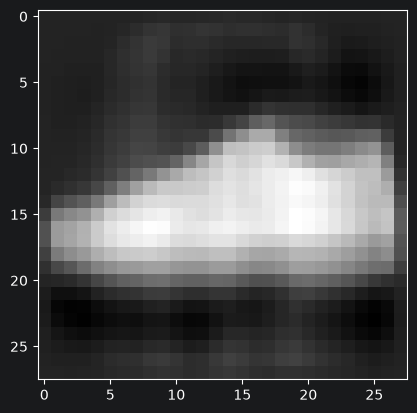

In [151]:
fig, ax = plt.subplots()
ax.imshow(model_img.reshape(28, 28), cmap="gray")
plt.show()